# Part 1: Data Preparation and Exploratory Analysis

**Data science project: Predicting 30-Day Hospital Readmission for Patients with Diabetes**

**Name:** Bernard Issifu

This notebook introduces the dataset, cleans it, engineers the features used later, and explores how
early readmission relates to patient and hospital-stay characteristics. The same steps are implemented
in R in `r/01_data_preparation_eda.Rmd`.

In [1]:
# ---- Setup ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

---
# 1. The dataset

The **Diabetes 130-US Hospitals for Years 1999–2008** dataset (Strack et al., 2014; UCI Machine Learning
Repository, CC BY 4.0) contains 101,766 hospital encounters of patients diagnosed with diabetes, drawn
from 130 US hospitals. Each row is one inpatient stay of 1–14 days in which laboratory tests were run and
medications given. The 50 columns describe the patient (age band, gender, race), the stay (admission
type and source, length of stay, numbers of lab tests, procedures and medications), the patient's prior
use of care (outpatient, emergency and inpatient visits in the preceding year), up to three ICD-9
diagnosis codes, two glucose tests (HbA1c and maximum serum glucose), and whether each of 23 diabetes
medications was prescribed, increased, decreased or kept steady.

The outcome is `readmitted`: whether the patient returned to hospital **within 30 days** (`<30`), **after
30 days** (`>30`), or **not at all** (`NO`). Early (30-day) readmission matters because it is costly,
often preventable, and used by US hospitals as a quality measure.

In [2]:
# '?' marks missing values. The text 'None' is a real category (test not performed), so pandas'
# default missing-value strings are switched off to keep it.
raw = pd.read_csv("../data/diabetic_data.csv", na_values=["?"], keep_default_na=False, low_memory=False)
print(raw.shape)
print(f"Unique patients: {raw['patient_nbr'].nunique():,}")
raw.head()

(101766, 50)
Unique patients: 71,518


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
# Outcome distribution in the raw data
raw["readmitted"].value_counts().to_frame("encounters").assign(
    percent=lambda t: (t["encounters"] / t["encounters"].sum() * 100).round(1))

,encounters,percent
readmitted,,
NO,54864,53.9
>30,35545,34.9
<30,11357,11.2


---
# 2. Data quality

## 2.1 Missing values

In [4]:
missing = (raw.isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False).to_frame("pct_missing")
missing

,pct_missing
weight,96.9
medical_specialty,49.1
payer_code,39.6
race,2.2
diag_3,1.4
diag_2,0.4


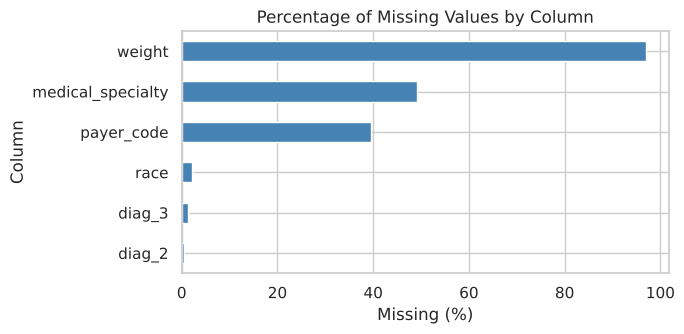

In [5]:
ax = missing["pct_missing"].plot(kind="barh", color="steelblue", figsize=(7, 3.5))
ax.invert_yaxis()
ax.set_title("Percentage of Missing Values by Column")
ax.set_xlabel("Missing (%)")
ax.set_ylabel("Column")
plt.tight_layout()
plt.show()

In [6]:
# 'None' in the two glucose tests means the test was not done; it is not missing data
for col in ["A1Cresult", "max_glu_serum"]:
    print(col, raw[col].value_counts().to_dict())

A1Cresult {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}
max_glu_serum {'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}


**Interpretation.** `weight` is missing for 96.9% of encounters and cannot be used. `payer_code`
(39.6%) is administrative rather than clinical, and `medical_specialty` (49.1%) is missing for about half
the stays. `race` and the secondary diagnoses have small gaps. The glucose tests look sparse but are
complete: `None` means the test was not ordered (83% of stays for HbA1c, 95% for serum glucose), which is
itself information about the care the patient received.

---
# 3. Cleaning

Each step below states what it does and why.

In [7]:
df = raw.copy()
steps = [("Raw data", len(df))]

# (1) Remove encounters ending in death or hospice care: these patients cannot be readmitted,
#     so keeping them would bias the readmission rate downward.
#     Discharge codes 11, 19, 20, 21 = expired; 13, 14 = hospice.
df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
steps.append(("Remove expired / hospice discharges", len(df)))

# (2) Remove the 3 records with gender 'Unknown/Invalid'
df = df[df["gender"] != "Unknown/Invalid"]
steps.append(("Remove invalid gender", len(df)))

# (3) Keep only each patient's first encounter. Repeat stays of the same patient are not independent
#     observations, and their outcomes are linked to the earlier stay.
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")
steps.append(("Keep first encounter per patient", len(df)))

pd.DataFrame(steps, columns=["step", "rows"])

,step,rows
0,Raw data,101766
1,Remove expired / hospice discharges,99343
2,Remove invalid gender,99340
3,Keep first encounter per patient,69987


In [8]:
# (4) Drop columns that are mostly missing, identifiers, or administrative
df = df.drop(columns=["weight", "payer_code", "encounter_id", "patient_nbr"])

# (5) Columns with a single value carry no information (three medications are never prescribed
#     to any patient in the cleaned data)
constant = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns dropped:", constant)
df = df.drop(columns=constant)

# (6) Missing race becomes its own category rather than dropping 1,500+ patients
df["race"] = df["race"].fillna("Unknown")

# (7) Medical specialty: keep the 10 most common, group the rest as 'Other', label missing as 'Missing'
top_spec = df["medical_specialty"].value_counts().head(10).index
df["medical_specialty"] = np.where(df["medical_specialty"].isna(), "Missing",
                                   np.where(df["medical_specialty"].isin(top_spec),
                                            df["medical_specialty"], "Other"))
print(df["medical_specialty"].value_counts().to_dict())

Constant columns dropped: ['examide', 'citoglipton', 'glimepiride-pioglitazone']
{'Missing': 33652, 'InternalMedicine': 10641, 'Other': 5487, 'Family/GeneralPractice': 4978, 'Emergency/Trauma': 4393, 'Cardiology': 4207, 'Surgery-General': 2205, 'Orthopedics': 1128, 'Orthopedics-Reconstructive': 1041, 'Radiologist': 821, 'Nephrology': 797, 'Pulmonology': 637}


---
# 4. Feature engineering

In [9]:
# (a) Outcome: 1 if readmitted within 30 days, else 0 (both '>30' and 'NO' count as 0)
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

# (b) Age band '[70-80)' -> midpoint 75, so age can be used as a number
df["age_years"] = df["age"].str.extract(r"\[(\d+)-").astype(int)[0] + 5

# (c) ICD-9 diagnosis codes (700+ distinct values) grouped into 9 clinical categories,
#     following the groups used by Strack et al. (2014)
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    if code[0] in "VE":            # supplementary classification codes
        return "Other"
    x = float(code)
    if 390 <= x <= 459 or int(x) == 785:
        return "Circulatory"
    if 460 <= x <= 519 or int(x) == 786:
        return "Respiratory"
    if 520 <= x <= 579 or int(x) == 787:
        return "Digestive"
    if int(x) == 250:
        return "Diabetes"
    if 800 <= x <= 999:
        return "Injury"
    if 710 <= x <= 739:
        return "Musculoskeletal"
    if 580 <= x <= 629 or int(x) == 788:
        return "Genitourinary"
    if 140 <= x <= 239:
        return "Neoplasms"
    return "Other"

for i in (1, 2, 3):
    df[f"diag{i}_group"] = df[f"diag_{i}"].map(icd9_group)
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])

# (d) Total prior-year visits (outpatient + emergency + inpatient)
df["prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]

# (e) Number of diabetes medications whose dose was changed (Up or Down) during the stay
med_cols = [c for c in df.columns if set(df[c].unique()) <= {"No", "Steady", "Up", "Down"}]
df["n_med_changes"] = df[med_cols].isin(["Up", "Down"]).sum(axis=1)
print(f"{len(med_cols)} medication columns")

# (f) Readable labels for the three coded ID columns (grouped into broad categories)
df["admission_type"] = df["admission_type_id"].map(
    {1: "Emergency", 2: "Urgent", 3: "Elective", 7: "Emergency"}).fillna("Other/Unknown")
df["discharge_to"] = df["discharge_disposition_id"].map(
    {1: "Home", 6: "Home with health service", 8: "Home with health service",
     3: "Care facility", 4: "Care facility", 5: "Care facility", 22: "Care facility",
     23: "Care facility", 24: "Care facility", 2: "Other hospital", 10: "Other hospital"}
).fillna("Other/Unknown")
df["admission_source"] = df["admission_source_id"].map(
    {7: "Emergency room", 1: "Referral", 2: "Referral", 3: "Referral",
     4: "Transfer", 5: "Transfer", 6: "Transfer", 10: "Transfer", 22: "Transfer", 25: "Transfer"}
).fillna("Other/Unknown")
df = df.drop(columns=["admission_type_id", "discharge_disposition_id", "admission_source_id"])

print(df.shape)
df.head()

20 medication columns
(69987, 47)


,race,gender,age,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,readmit_30,age_years,diag1_group,diag2_group,diag3_group,prior_visits,n_med_changes,admission_type,discharge_to,admission_source
8,Caucasian,Female,[80-90),13,Missing,68,2,28,0,0,...,0,85,Circulatory,Circulatory,Other,0,0,Urgent,Home,Transfer
9,Caucasian,Female,[90-100),12,InternalMedicine,33,3,18,0,0,...,0,95,Circulatory,Neoplasms,Respiratory,0,0,Elective,Care facility,Transfer
4,Caucasian,Male,[40-50),1,Missing,51,0,8,0,0,...,0,45,Neoplasms,Neoplasms,Diabetes,0,0,Emergency,Home,Emergency room
10,AfricanAmerican,Female,[40-50),9,Missing,47,2,17,0,0,...,0,45,Diabetes,Circulatory,Injury,0,0,Emergency,Home,Emergency room
5,Caucasian,Male,[50-60),3,Missing,31,6,16,0,0,...,0,55,Circulatory,Circulatory,Diabetes,0,0,Urgent,Home,Referral


In [10]:
print("Missing values remaining:", int(df.isna().sum().sum()))
print(f"30-day readmission rate after cleaning: {df['readmit_30'].mean():.2%}")

Missing values remaining: 0
30-day readmission rate after cleaning: 8.98%


**Interpretation.** Cleaning leaves **69,987 patients** (one encounter each) and no missing values. The
30-day readmission rate falls from 11.2% in the raw data to **8.98%**, because patients with many
repeat stays, who are the most often readmitted, now count once. The outcome is imbalanced (about 1 in
11 patients), which the models in Part 2 will have to account for.

---
# 5. Exploratory analysis

## 5.1 Readmission by prior inpatient visits and by age

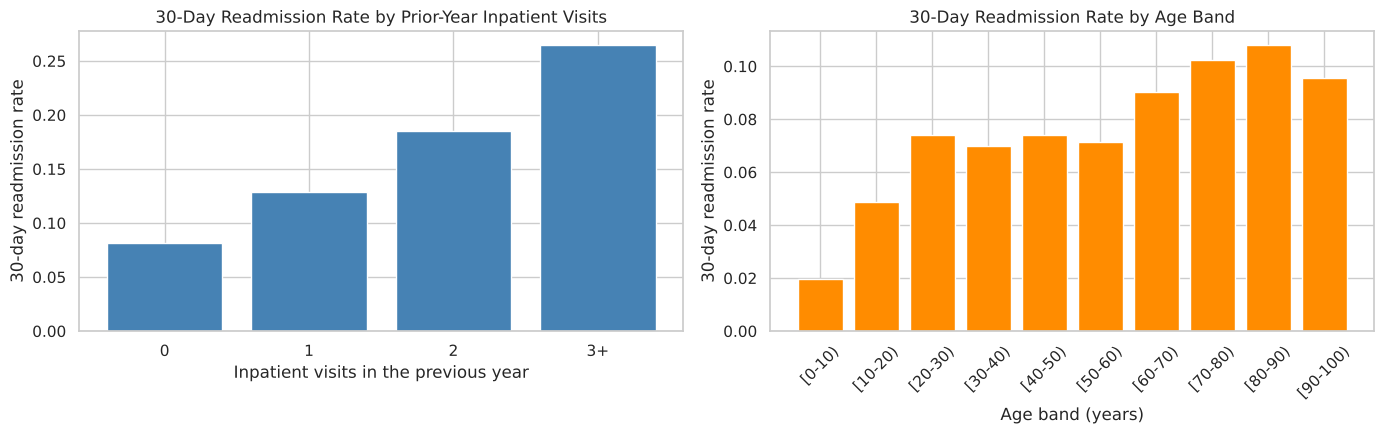

,patients,rate
prior_inpatient,,
0,61792,0.081
1,5798,0.129
2,1501,0.185
3+,896,0.265


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

inp = df.assign(prior_inpatient=df["number_inpatient"].clip(upper=3).astype(str).replace({"3": "3+"}))
rate_inp = inp.groupby("prior_inpatient")["readmit_30"].mean()
axes[0].bar(rate_inp.index, rate_inp.values, color="steelblue")
axes[0].set_title("30-Day Readmission Rate by Prior-Year Inpatient Visits")
axes[0].set_xlabel("Inpatient visits in the previous year")
axes[0].set_ylabel("30-day readmission rate")

rate_age = df.groupby("age")["readmit_30"].mean()
axes[1].bar(rate_age.index, rate_age.values, color="darkorange")
axes[1].set_title("30-Day Readmission Rate by Age Band")
axes[1].set_xlabel("Age band (years)")
axes[1].set_ylabel("30-day readmission rate")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

inp.groupby("prior_inpatient")["readmit_30"].agg(patients="size", rate="mean").round(3)

**Interpretation.** Prior hospital use is the clearest signal so far: the readmission rate rises from
8.1% for patients with no inpatient visit in the previous year to 12.9% (one visit), 18.5% (two) and
26.5% (three or more). Readmission also increases with age, from about 7% in the 20–60 bands to
around 10% for patients aged 70–90 (the youngest bands have very few patients).

## 5.2 Readmission by discharge destination and primary diagnosis

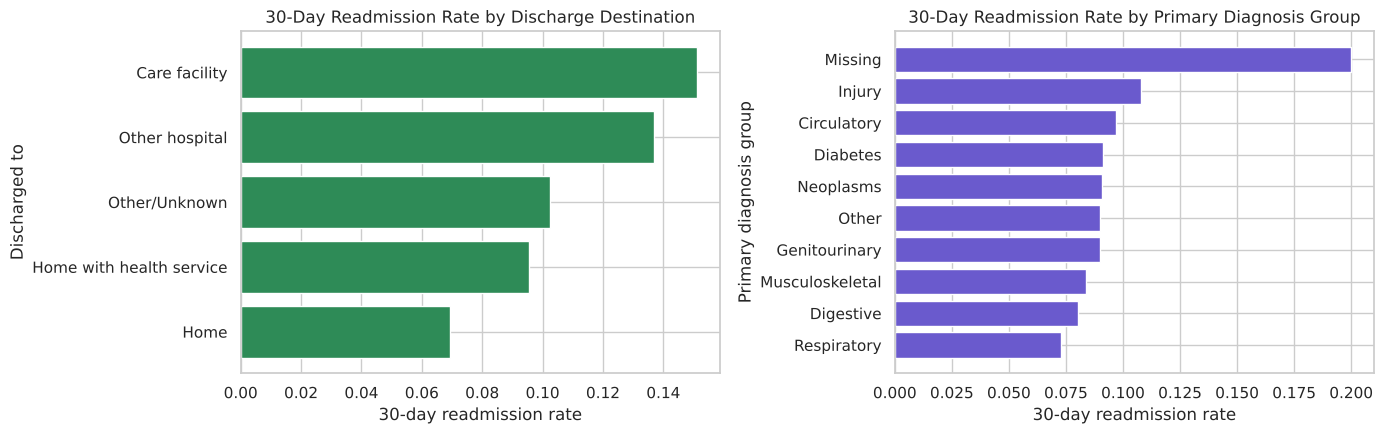

,patients,rate
discharge_to,,
Home,44320,0.069
Home with health service,8364,0.095
Other/Unknown,3816,0.102
Other hospital,1547,0.137
Care facility,11940,0.151


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

rate_dis = df.groupby("discharge_to")["readmit_30"].mean().sort_values()
axes[0].barh(rate_dis.index, rate_dis.values, color="seagreen")
axes[0].set_title("30-Day Readmission Rate by Discharge Destination")
axes[0].set_xlabel("30-day readmission rate")
axes[0].set_ylabel("Discharged to")

rate_diag = df.groupby("diag1_group")["readmit_30"].mean().sort_values()
axes[1].barh(rate_diag.index, rate_diag.values, color="slateblue")
axes[1].set_title("30-Day Readmission Rate by Primary Diagnosis Group")
axes[1].set_xlabel("30-day readmission rate")
axes[1].set_ylabel("Primary diagnosis group")

plt.tight_layout()
plt.show()

df.groupby("discharge_to")["readmit_30"].agg(patients="size", rate="mean").round(3).sort_values("rate")

**Interpretation.** Patients discharged home have the lowest readmission rate; those sent to a care
facility or another hospital are readmitted far more often, which likely reflects how ill they were at
discharge. Differences between primary diagnosis groups are smaller (injury and circulatory conditions
are highest, respiratory lowest). The tiny 'Missing' group (10 patients) should not be read into.

## 5.3 Distributions of the numeric features

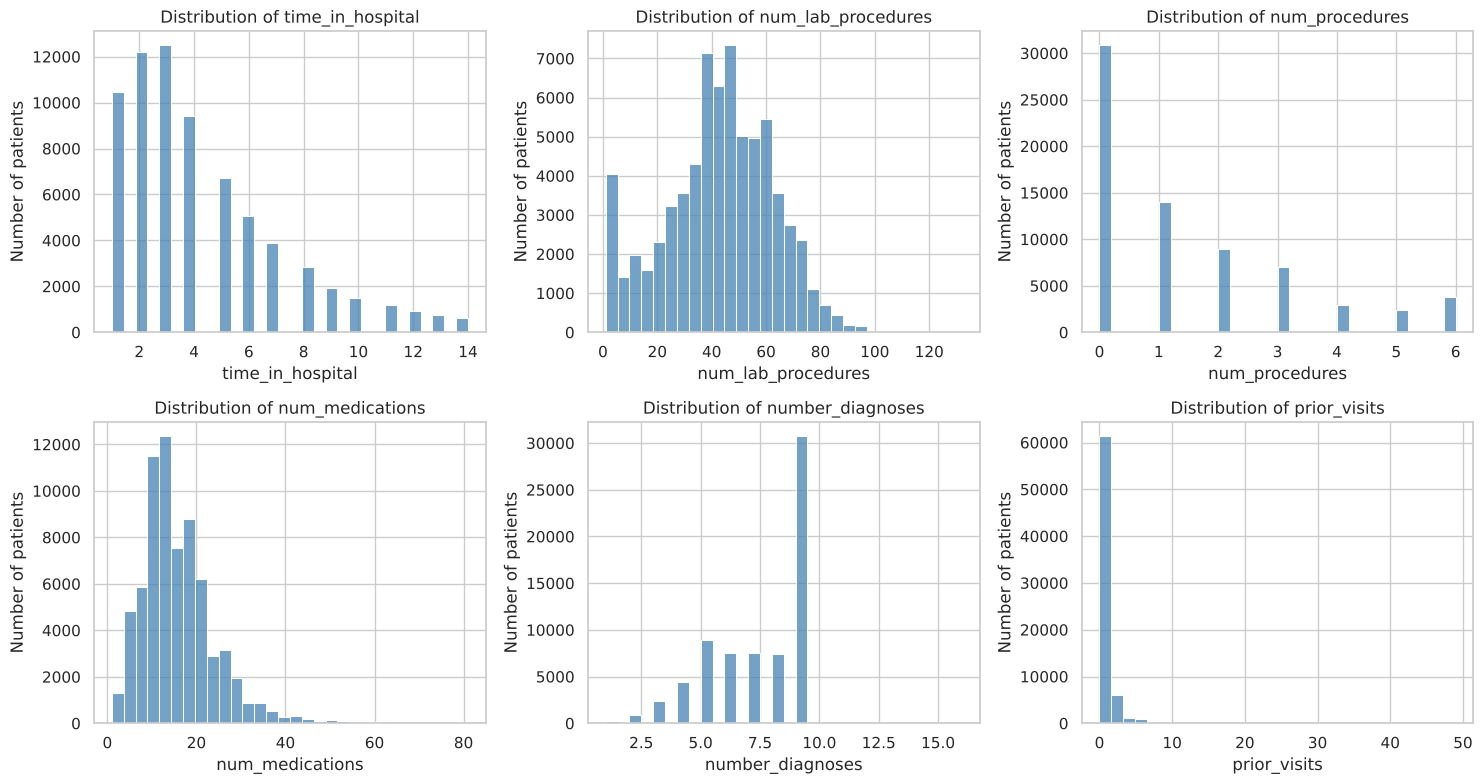

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69987.0,4.27,2.93,1.0,2.0,3.0,6.0,14.0
num_lab_procedures,69987.0,42.88,19.89,1.0,31.0,44.0,57.0,132.0
num_procedures,69987.0,1.43,1.76,0.0,0.0,1.0,2.0,6.0
num_medications,69987.0,15.67,8.29,1.0,10.0,14.0,20.0,81.0
number_diagnoses,69987.0,7.22,2.00,1.0,6.0,8.0,9.0,16.0
prior_visits,69987.0,0.56,1.43,0.0,0.0,0.0,1.0,49.0


In [13]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_diagnoses", "prior_visits"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of patients")
plt.tight_layout()
plt.show()

df[num_cols].describe().round(2).T

**Interpretation.** Length of stay, medications and prior visits are right-skewed (most patients sit at
the low end, with a long tail), while lab procedures are roughly bell-shaped. `prior_visits` is
especially skewed, with most patients at zero; Part 2 will consider a log transform or binning for these
features.

## 5.4 Do readmitted patients differ on the numeric features?

In [14]:
df.groupby("readmit_30")[num_cols].mean().round(2).T.rename(
    columns={0: "Not readmitted (mean)", 1: "Readmitted <30 days (mean)"})

readmit_30,Not readmitted (mean),Readmitted <30 days (mean)
time_in_hospital,4.22,4.79
num_lab_procedures,42.68,44.91
num_procedures,1.43,1.42
num_medications,15.57,16.62
number_diagnoses,7.20,7.51
prior_visits,0.53,0.83


**Interpretation.** Patients readmitted within 30 days had slightly longer stays, more medications and
diagnoses, and clearly more prior-year visits on average. No single feature separates the groups well,
which is typical for readmission data and motivates combining features in a model.

In [15]:
# Save the cleaned data for Parts 2 and 3
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/diabetes_clean_python.csv", index=False)
print("Saved", df.shape)

Saved (69987, 47)


---
# 6. Summary and the two project questions

The cleaned dataset has 69,987 patients and no missing values, with an imbalanced outcome (8.98%
readmitted within 30 days). Prior hospital use, discharge destination and age show the strongest
links to early readmission.

The project will address two questions:

1. **Which patient and hospital-stay factors best predict readmission within 30 days?**
   Classification (logistic regression, decision tree, random forest) with methods for the imbalanced
   outcome, evaluated with ROC-AUC, recall and precision on a stratified test set.
2. **Which combinations of patient characteristics and treatments are associated with early
   readmission?** Association rule mining (Apriori) with `readmitted <30` as the rule consequent,
   ranked by lift.